<a href="https://colab.research.google.com/github/NataliaGon/research/blob/main/regenerative_tourism.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import re
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mticker
from urllib.parse import urlparse
from google.colab import drive
from sklearn.preprocessing import MultiLabelBinarizer, OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.preprocessing import Normalizer
from scipy.sparse import csr_matrix, hstack
from scipy.sparse import hstack, csr_matrix
from wordcloud import WordCloud
from sentence_transformers import SentenceTransformer
from sklearn.decomposition import PCA


In [ ]:
drive.mount('/content/gdrive')
df=pd.read_csv('gdrive/My Drive/Extraordinary Ability/Speaker/Geneva forum/ML/green-spots6.csv')

Mounted at /content/gdrive


In [ ]:
BAR_COLOR = "#4285F4"



plt.style.use("seaborn-v0_8-whitegrid")

mpl.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "grid.linewidth": 0.7,
    "grid.linestyle": "--",
    "axes.titleweight": "normal",
    "axes.labelweight": "normal",
})
mpl.rcParams["axes.labelpad"] = 20


# Fields

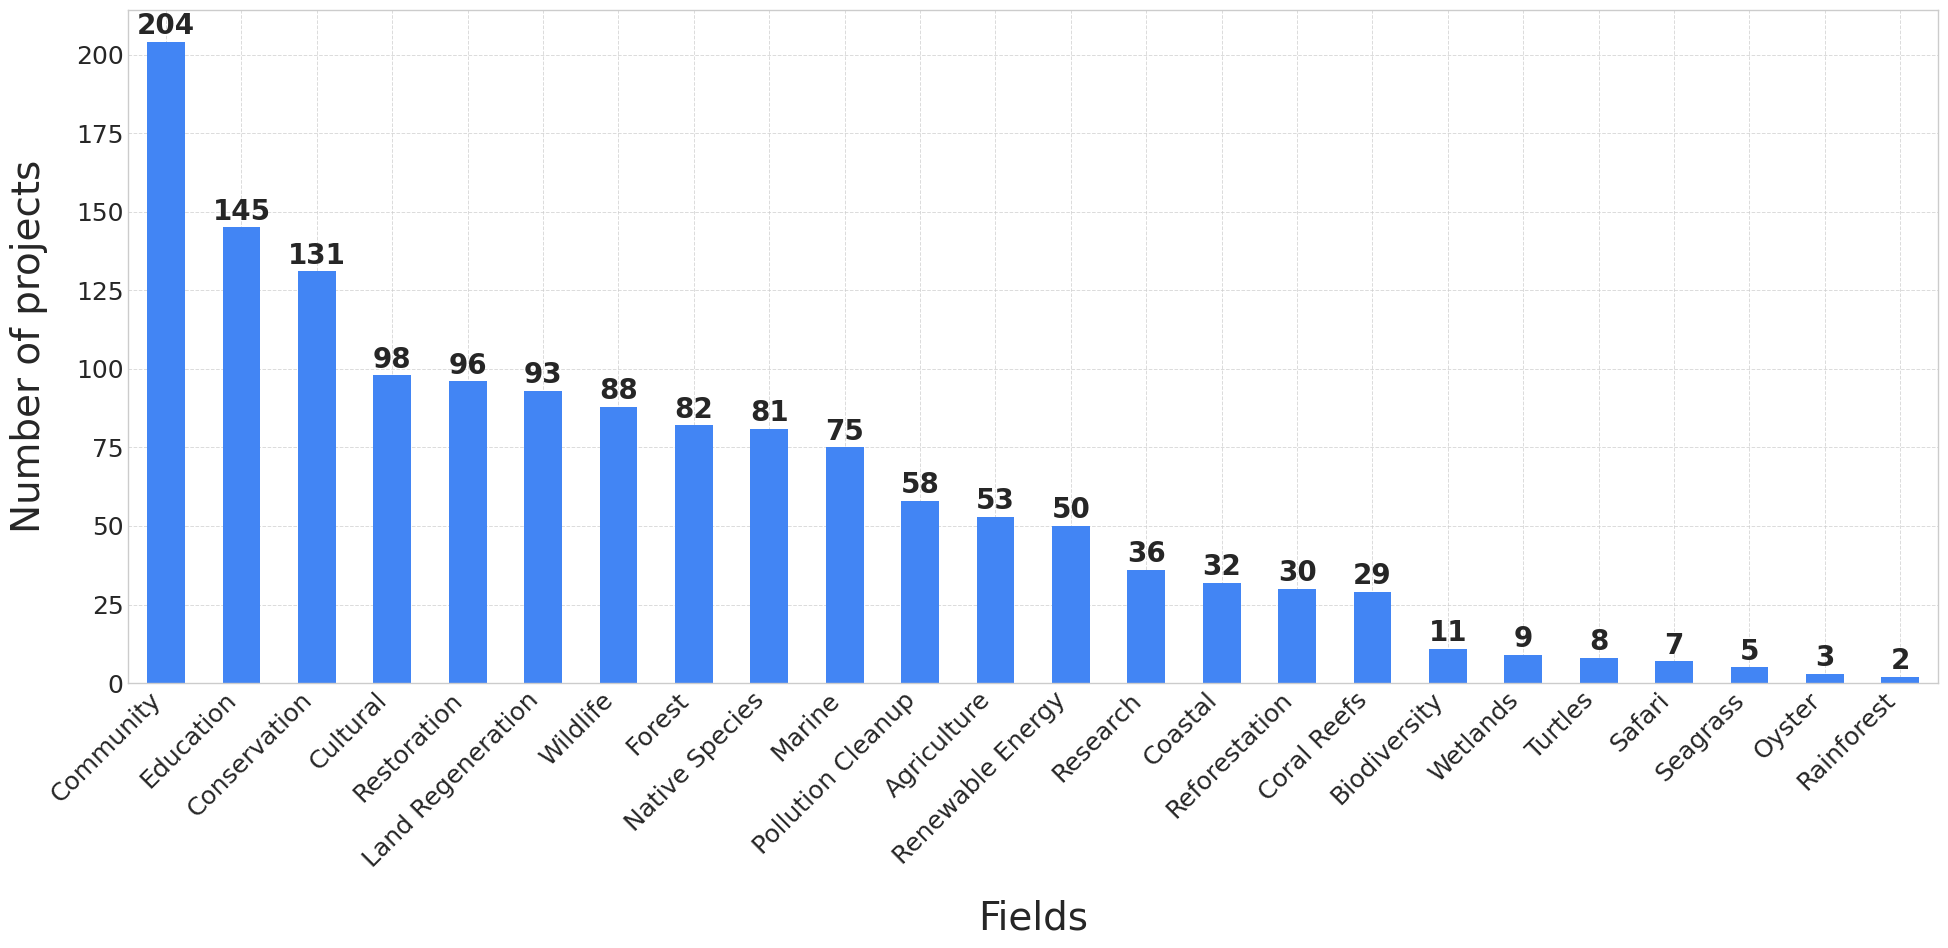

In [ ]:


# 🔹 Global presentation-friendly settings
plt.rcParams.update({
    "figure.figsize": (20, 10),   # big canvas for projector
    "font.size": 24,              # base font
    "axes.labelsize": 28,         # labels "Fields", "Number of projects"
    "xtick.labelsize": 18,        # x-axis tick labels
    "ytick.labelsize": 18,        # y-axis tick labels
})

all_fields = []

for row in df["fields"].dropna():
    if isinstance(row, list):
        parts = row
    else:
        parts = str(row).split(",")

    for f in parts:
        name = str(f).strip()
        if name:
            all_fields.append(name.lower())

field_counts = pd.Series(all_fields).value_counts()
field_counts.index = field_counts.index.str.title()

# Create large figure
fig, ax = plt.subplots()

ax = field_counts.plot(kind="bar", color=BAR_COLOR, ax=ax)

plt.xlabel("Fields")
plt.ylabel("Number of projects")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="both", linestyle="--", alpha=0.7)

# Add numbers above bars with large font
for i, v in enumerate(field_counts.values):
    ax.text(
        i,
        v + 0.5,
        str(v),
        ha="center",
        va="bottom",
        fontsize=20,      # bigger for projector
        fontweight="bold",
    )

fig.tight_layout()

# 🔹 High-quality exports
fig.savefig("fields_histogram_600dpi.png", dpi=600, bbox_inches="tight")  # for PPTX/Slides
fig.savefig("fields_histogram.svg", bbox_inches="tight")                  # vector
fig.savefig("fields_histogram.pdf", bbox_inches="tight")                  # vector backup

plt.show()


# Countries

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

def format_country(name: str) -> str:
    n = str(name).strip().lower()
    base = n.title()

    exceptions = {
        "usa": "USA",
        "uk": "UK",
        "uae": "UAE",
        "eu": "EU",
        "united kingdom": "United Kingdom",
    }
    if n in exceptions:
        return exceptions[n]
    return base


all_countries = []

for row in df["country"].dropna():
    if isinstance(row, list):
        parts = row
    else:
        parts = str(row).split(",")

    for c in parts:
        name = str(c).strip()
        if name:
            all_countries.append(name.lower())

country_counts = pd.Series(all_countries).value_counts()

print(country_counts)
country_counts.index.to_series().to_csv("country_list.csv", index=False)

stats = (
    country_counts
    .rename("projects")
    .reset_index()
    .rename(columns={"index": "country_norm"})
)

policy_national = {
    "costa rica",
    "new zealand",
    "palau",
    "australia",
    "slovenia",
    "finland",
    "sweden",
    "bhutan",
    "mexico",
}

policy_partial = {
    "usa",
    "united kingdom",
}

def policy_level(country_norm):
    if country_norm in policy_national:
        return 2   # strong / national
    if country_norm in policy_partial:
        return 1   # partial / sub-national
    return 0       # none

stats["policy_level"] = stats["country_norm"].apply(policy_level)

def label_with_star(row):
    base = format_country(row["country_norm"])
    if row["policy_level"] == 2:
        return base + " ★★"   # national
    if row["policy_level"] == 1:
        return base + " ★"    # partial
    return base

top20 = stats.nlargest(20, "projects").copy()
top20["label"] = top20.apply(label_with_star, axis=1)
top20 = top20.set_index("label")

# 🔹 Big figure + big fonts for projector
plt.rcParams.update({
    "figure.figsize": (20, 10),
    "font.size": 24,
    "axes.labelsize": 28,
    "xtick.labelsize": 18,
    "ytick.labelsize": 18,
})

fig, ax = plt.subplots()

ax = top20["projects"].plot(kind="bar", color=BAR_COLOR, ax=ax)

# 🔹 Add headroom above tallest bar
y_max = top20["projects"].max()
ax.set_ylim(0, y_max * 1.15)   # 15% extra space at the top

plt.xlabel("Country  (★★ = national policy, ★ = sub-national policy)")
plt.ylabel("Number of projects")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.7)

# labels above bars
for i, v in enumerate(top20["projects"].values):
    ax.text(
        i,
        v + 0.3,
        str(v),
        ha="center",
        va="bottom",
        fontsize=20,
        fontweight="bold",
    )

fig.tight_layout()

# 🔹 High-quality exports
fig.savefig("country.png", dpi=600, bbox_inches="tight")
fig.savefig("country.svg", bbox_inches="tight")

plt.show()
country_counts_df = (
    country_counts
    .rename_axis("country_norm")      # index name → country_norm
    .reset_index(name="projects")     # turn into DataFrame with 2 columns
)

country_counts_df.to_csv("country_counts.csv", index=False)



NameError: name 'df' is not defined

usa               25
costa rica        21
australia         18
new zealand       14
united kingdom    11
                  ..
sudan              1
chad               1
nigeria            1
niger              1
sweden             1
Name: count, Length: 72, dtype: int64


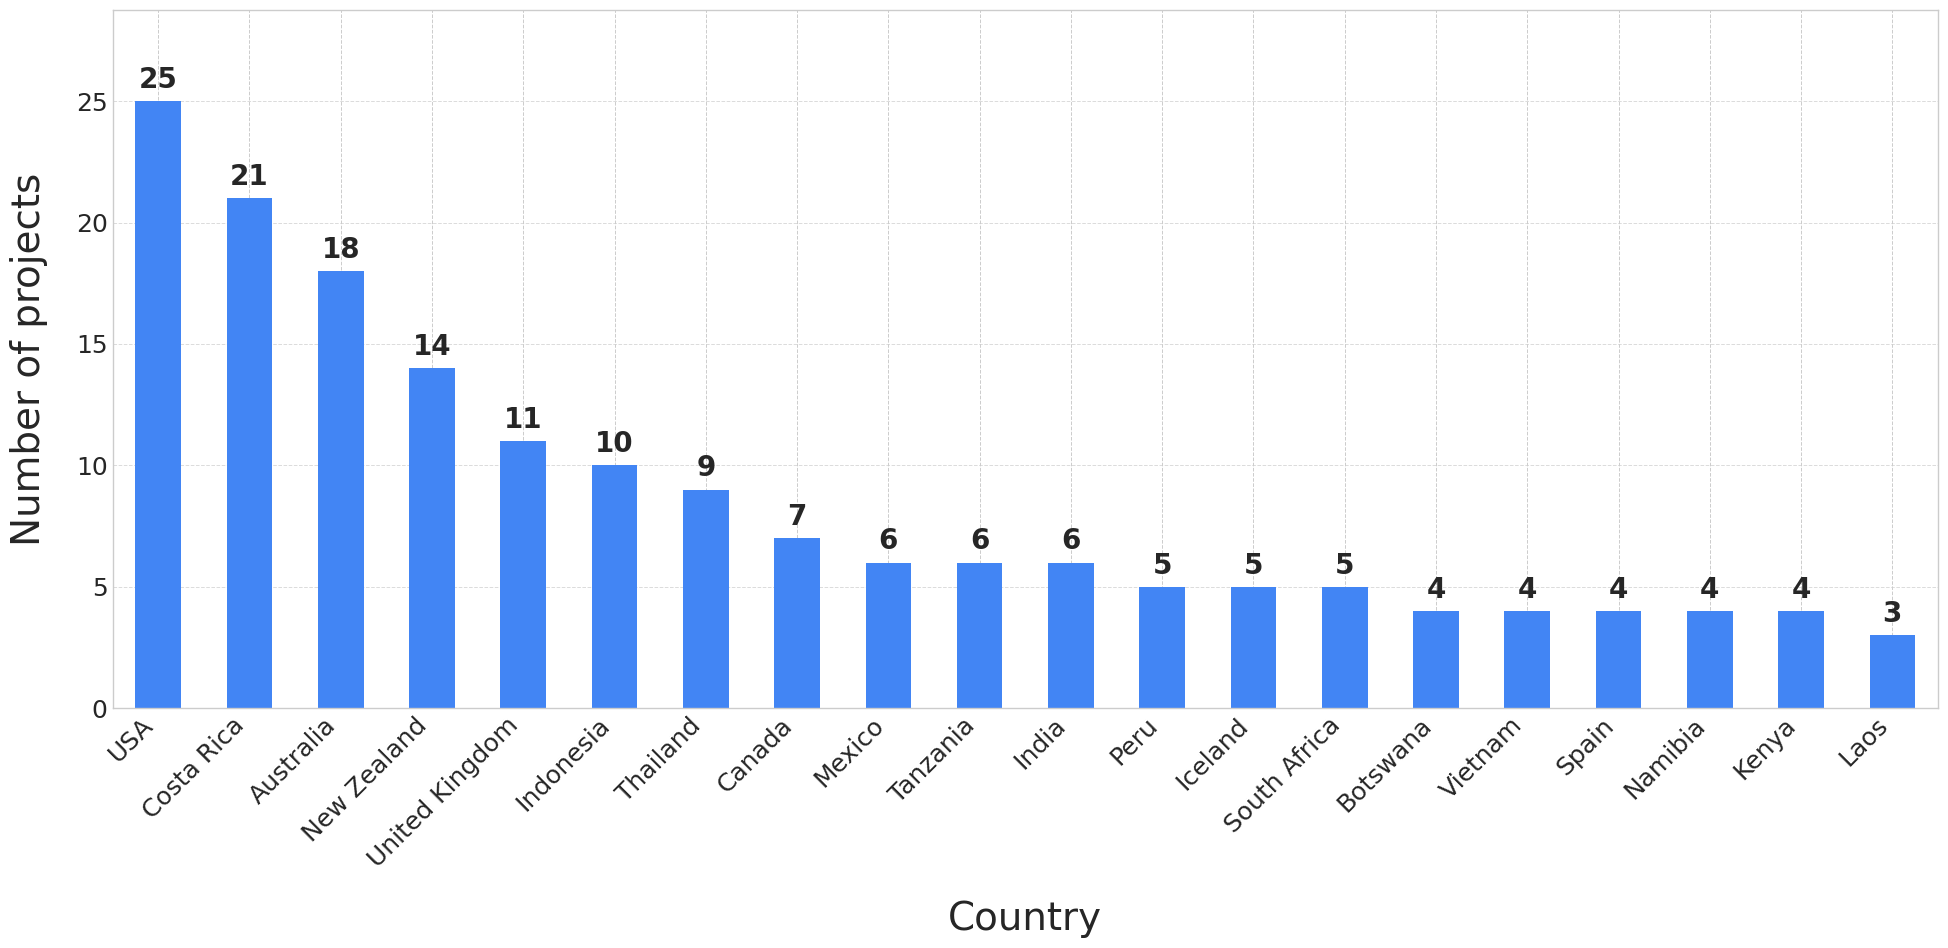

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

def format_country(name: str) -> str:
    n = str(name).strip().lower()
    base = n.title()

    exceptions = {
        "usa": "USA",
        "uk": "UK",
        "uae": "UAE",
        "eu": "EU",
        "united kingdom": "United Kingdom",
    }
    if n in exceptions:
        return exceptions[n]
    return base


all_countries = []

for row in df["country"].dropna():
    if isinstance(row, list):
        parts = row
    else:
        parts = str(row).split(",")

    for c in parts:
        name = str(c).strip()
        if name:
            all_countries.append(name.lower())

country_counts = pd.Series(all_countries).value_counts()

print(country_counts)
country_counts.index.to_series().to_csv("country_list.csv", index=False)

# ---- clean stats: NO policy, NO stars ----
stats = (
    country_counts
    .rename("projects")
    .reset_index()
    .rename(columns={"index": "country_norm"})
)

# Top 20 by number of projects
top20 = stats.nlargest(20, "projects").copy()
top20["label"] = top20["country_norm"].apply(format_country)
top20 = top20.set_index("label")

# 🔹 Big figure + big fonts for projector
plt.rcParams.update({
    "figure.figsize": (20, 10),
    "font.size": 24,
    "axes.labelsize": 28,
    "xtick.labelsize": 18,
    "ytick.labelsize": 18,
})

fig, ax = plt.subplots()

ax = top20["projects"].plot(kind="bar", color=BAR_COLOR, ax=ax)

# 🔹 Add headroom above tallest bar
y_max = top20["projects"].max()
ax.set_ylim(0, y_max * 1.15)   # 15% extra space at the top

plt.xlabel("Country")
plt.ylabel("Number of projects")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.7)

# labels above bars
for i, v in enumerate(top20["projects"].values):
    ax.text(
        i,
        v + 0.3,
        str(v),
        ha="center",
        va="bottom",
        fontsize=20,
        fontweight="bold",
    )

fig.tight_layout()

# 🔹 High-quality exports
fig.savefig("country.png", dpi=600, bbox_inches="tight")
fig.savefig("country.svg", bbox_inches="tight")

plt.show()


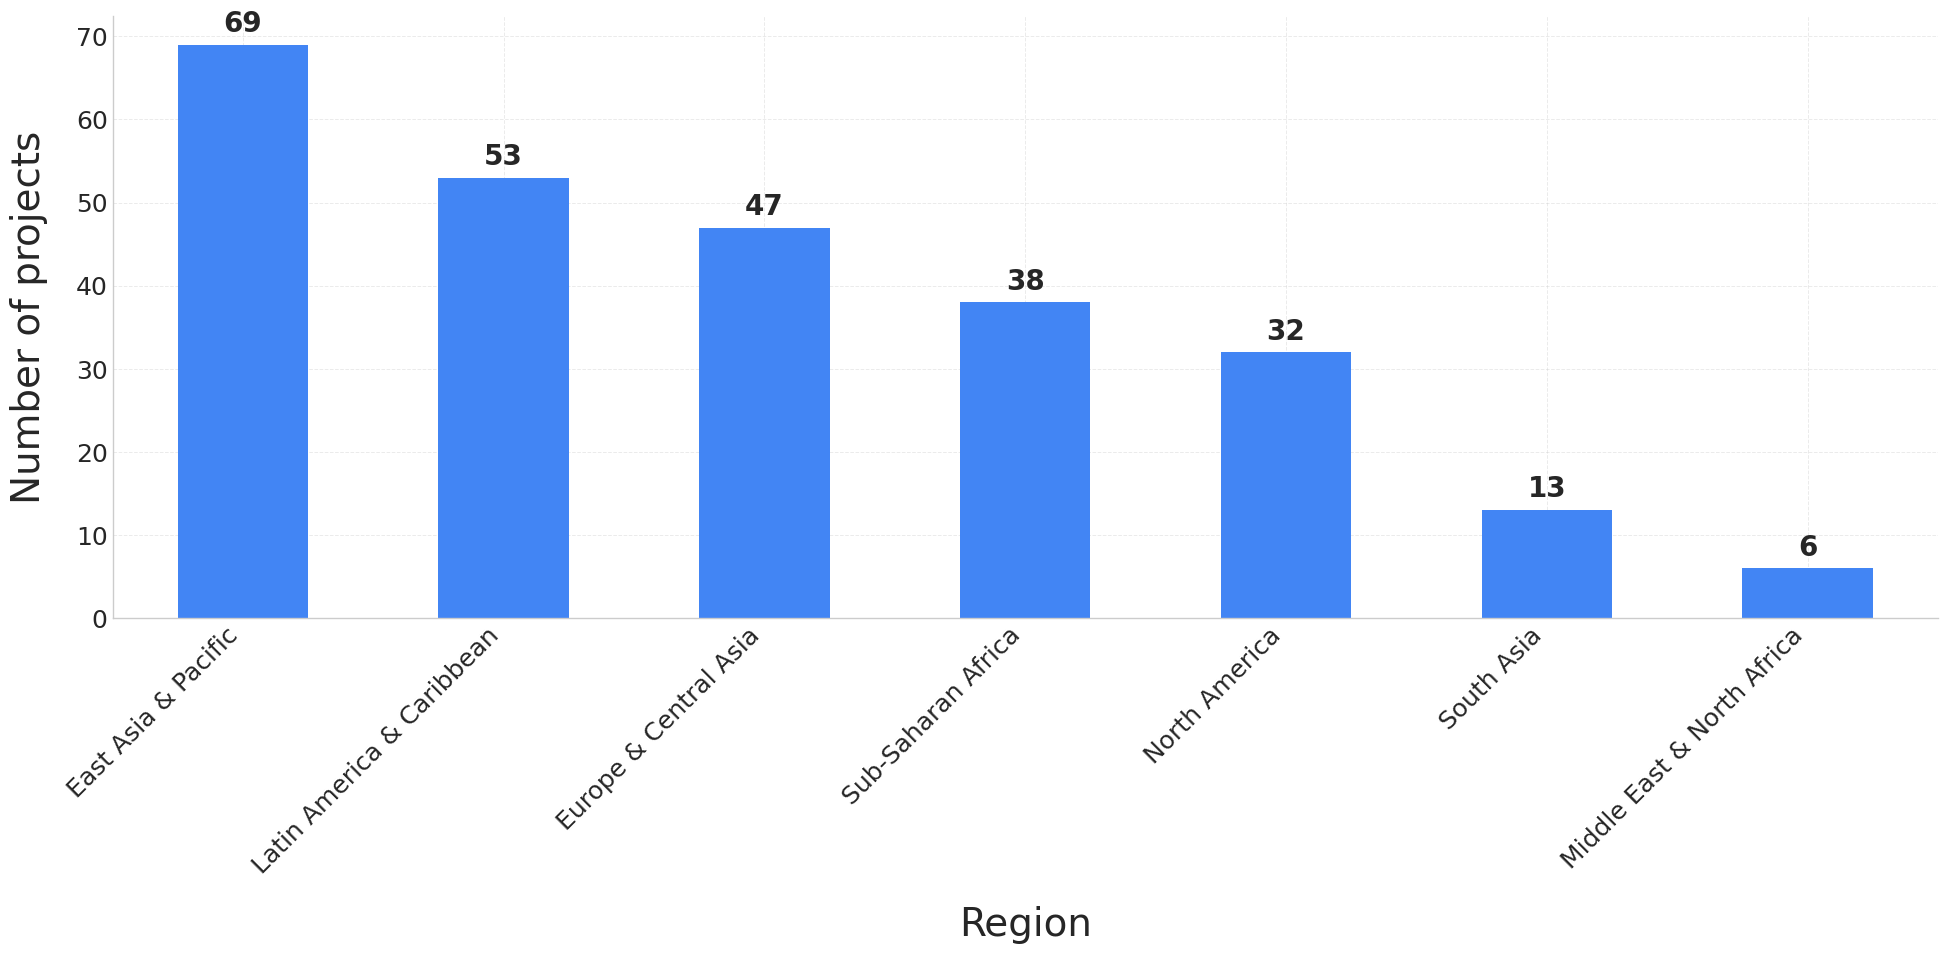

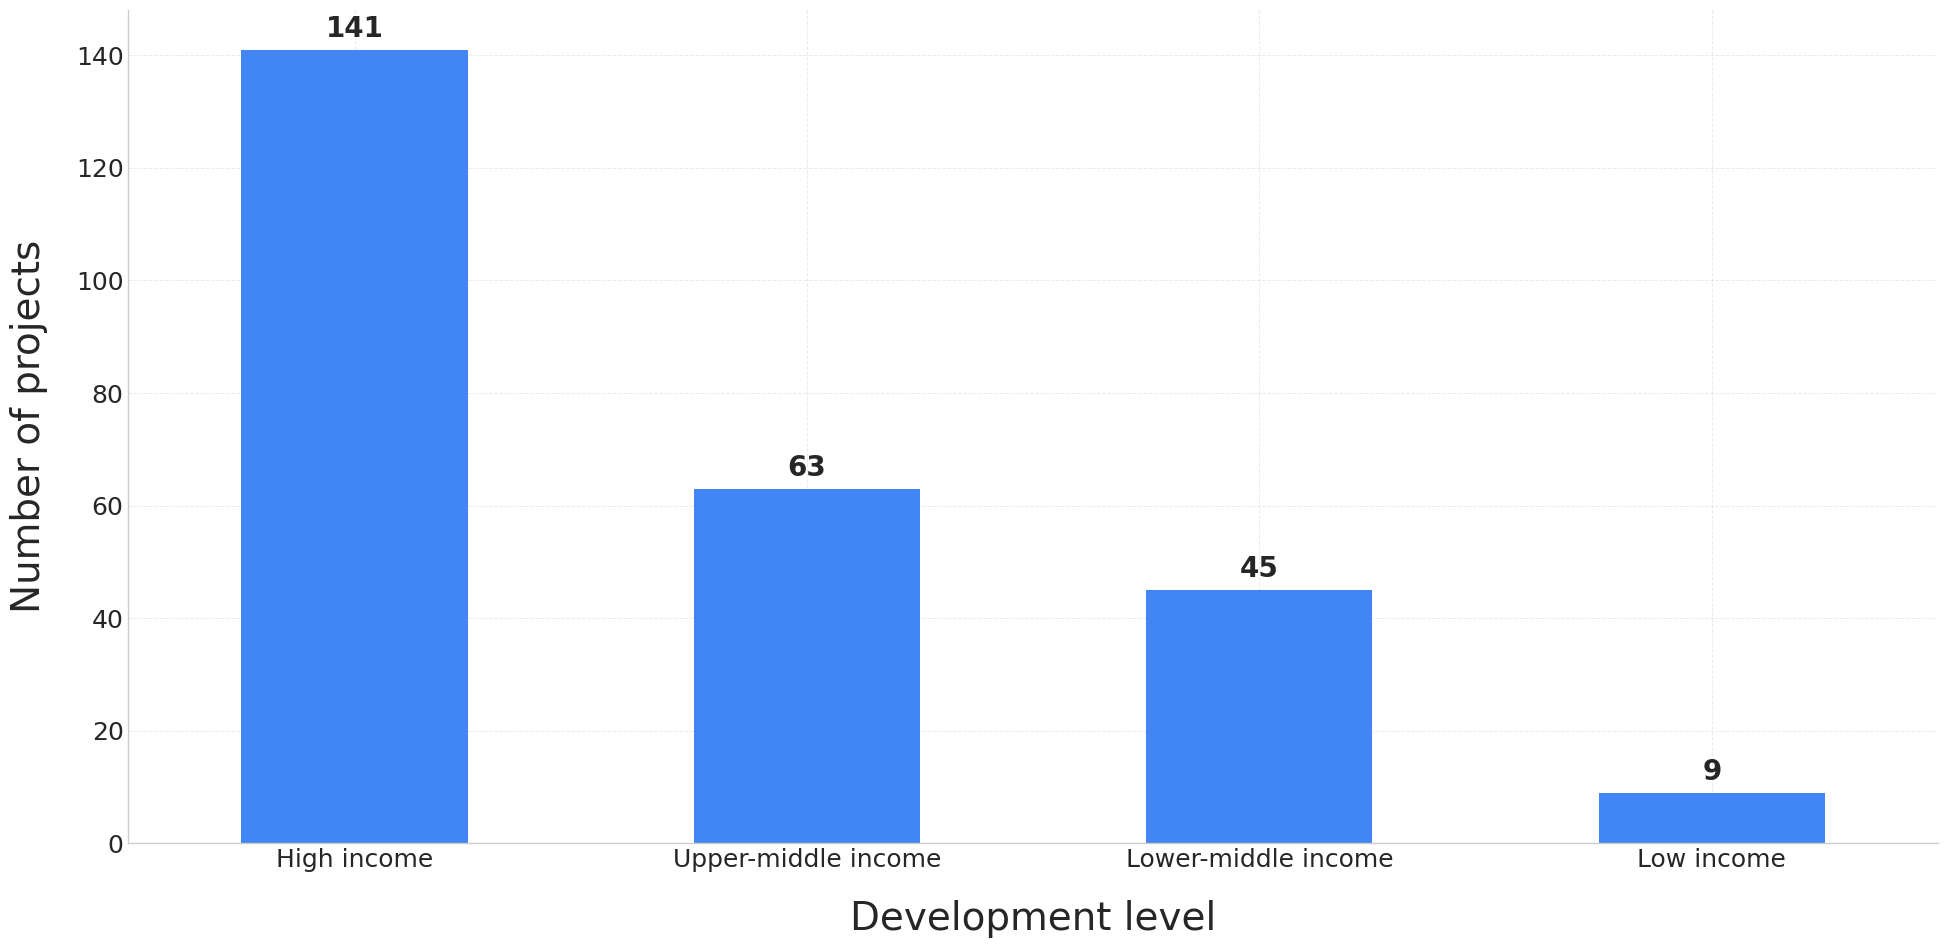

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

def add_value_labels(ax, fontsize=20, offset=5):
    for rect in ax.patches:
        height = rect.get_height()
        ax.annotate(
            f"{int(height)}",
            xy=(rect.get_x() + rect.get_width() / 2, height),
            xytext=(0, offset),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=fontsize,
            fontweight="bold"
        )

# 🔹 Global presentation-friendly settings
plt.rcParams.update({
    "figure.figsize": (20, 10),   # large canvas for projector
    "font.size": 24,              # base font
    "axes.labelsize": 28,         # axis labels
    "xtick.labelsize": 18,        # tick labels
    "ytick.labelsize": 18,
})

# =======================
# 1) Projects per region
# =======================

all_regions = []
for row in df["region"].dropna():
    if isinstance(row, list):
        parts = row
    else:
        parts = str(row).split(",")
    for r in parts:
        name = str(r).strip().rstrip(".")
        if name:
            all_regions.append(name)

region_counts = pd.Series(all_regions).value_counts()

fig, ax = plt.subplots()  # uses global figsize from rcParams
region_counts.plot(kind="bar", ax=ax, color=BAR_COLOR)

ax.set_xlabel("Region")
ax.set_ylabel("Number of projects")

ax.set_axisbelow(True)
ax.grid(axis="both", linestyle="--", alpha=0.4)

ax.tick_params(axis="x", rotation=45)
for label in ax.get_xticklabels():
    label.set_horizontalalignment("right")

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

add_value_labels(ax, fontsize=20, offset=5)
fig.tight_layout()

# 🔹 High-quality exports
fig.savefig("regions_600dpi.png", dpi=600, bbox_inches="tight")
fig.savefig("regions.svg", bbox_inches="tight")
fig.savefig("regions.pdf", bbox_inches="tight")

plt.show()

# ==========================================
# 2) Projects by country development level
# ==========================================

all_levels = []
for row in df["country_development_level"].dropna():
    if isinstance(row, list):
        parts = row
    else:
        parts = str(row).split(",")
    for lvl in parts:
        name = str(lvl).strip()
        if name:
            all_levels.append(name)

mapping = {
    "high income": "High income",
    "upper income": "Upper-middle income",
    "up income": "Upper-middle income",
    "upper-middle income": "Upper-middle income",
    "upper middle income": "Upper-middle income",
    "lower income": "Lower-middle income",
    "lower-middle income": "Lower-middle income",
    "lower middle income": "Lower-middle income",
    "low income": "Low income",
}

normalized_levels = [
    mapping.get(level.lower(), level.title()) for level in all_levels
]

dev_counts = pd.Series(normalized_levels).value_counts()
order = ["High income", "Upper-middle income", "Lower-middle income", "Low income"]
dev_counts = dev_counts.reindex(order).dropna()

fig, ax = plt.subplots()  # again uses large figsize from rcParams
dev_counts.plot(kind="bar", ax=ax, color=BAR_COLOR)

ax.set_xlabel("Development level")
ax.set_ylabel("Number of projects")

ax.set_axisbelow(True)
ax.grid(axis="both", linestyle="--", alpha=0.4)
ax.tick_params(axis="x", rotation=0)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

add_value_labels(ax, fontsize=20, offset=5)
fig.tight_layout()

# 🔹 High-quality exports
fig.savefig("development_levels_600dpi.png", dpi=600, bbox_inches="tight")
fig.savefig("development_levels.svg", bbox_inches="tight")
fig.savefig("development_levels.pdf", bbox_inches="tight")

plt.show()


# Correlation policy/projects

In [ ]:

policy_countries = {
    "costa rica",
    "new zealand",
    "palau",
    "australia",
    "slovenia",
    "finland",
    "sweden",
    "bhutan",
    "mexico",
    "usa",
    "united kingdom",
}


stats = (
    country_counts
    .rename("projects")
    .reset_index()
    .rename(columns={"index": "country_raw"})
)


stats["country_norm"] = stats["country_raw"].str.strip().str.lower()


stats["has_policy"] = stats["country_norm"].isin(policy_countries).astype(int)



stats["country_label"] = stats["country_norm"].apply(format_country)

stats.head()


,country_raw,projects,country_norm,has_policy,country_label
0,usa,25,usa,1,USA
1,costa rica,21,costa rica,1,Costa Rica
2,australia,18,australia,1,Australia
3,new zealand,14,new zealand,1,New Zealand
4,united kingdom,11,united kingdom,1,United Kingdom


In [ ]:
corr = stats["projects"].corr(stats["has_policy"])
print("Correlation between number of projects and having policy:", corr)


Correlation between number of projects and having policy: 0.5537623116956317


/tmp/ipython-input-523847040.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


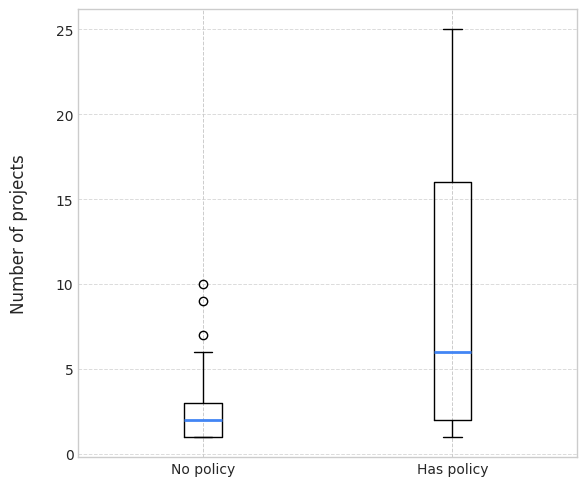

In [ ]:
plt.figure(figsize=(6, 5))



data_no_policy = stats.loc[stats["has_policy"] == 0, "projects"]
data_policy    = stats.loc[stats["has_policy"] == 1, "projects"]

# plt.boxplot(
#     [data_no_policy, data_policy],
#     labels=["No policy", "Has policy"]
# )

plt.boxplot(
    [data_no_policy, data_policy],
    labels=["No policy", "Has policy"],
    medianprops=dict(color=BAR_COLOR, linewidth=2),
    boxprops=dict(color="black"),
    whiskerprops=dict(color="black"),
    capprops=dict(color="black"),
    flierprops=dict(markeredgecolor="black"),
)


# plt.title("Projects distribution in countries\nwith and without regenerative policies")
plt.ylabel("Number of projects")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()


# WEBSITE DOMAIN EXTRACTION & VISUALIZATION

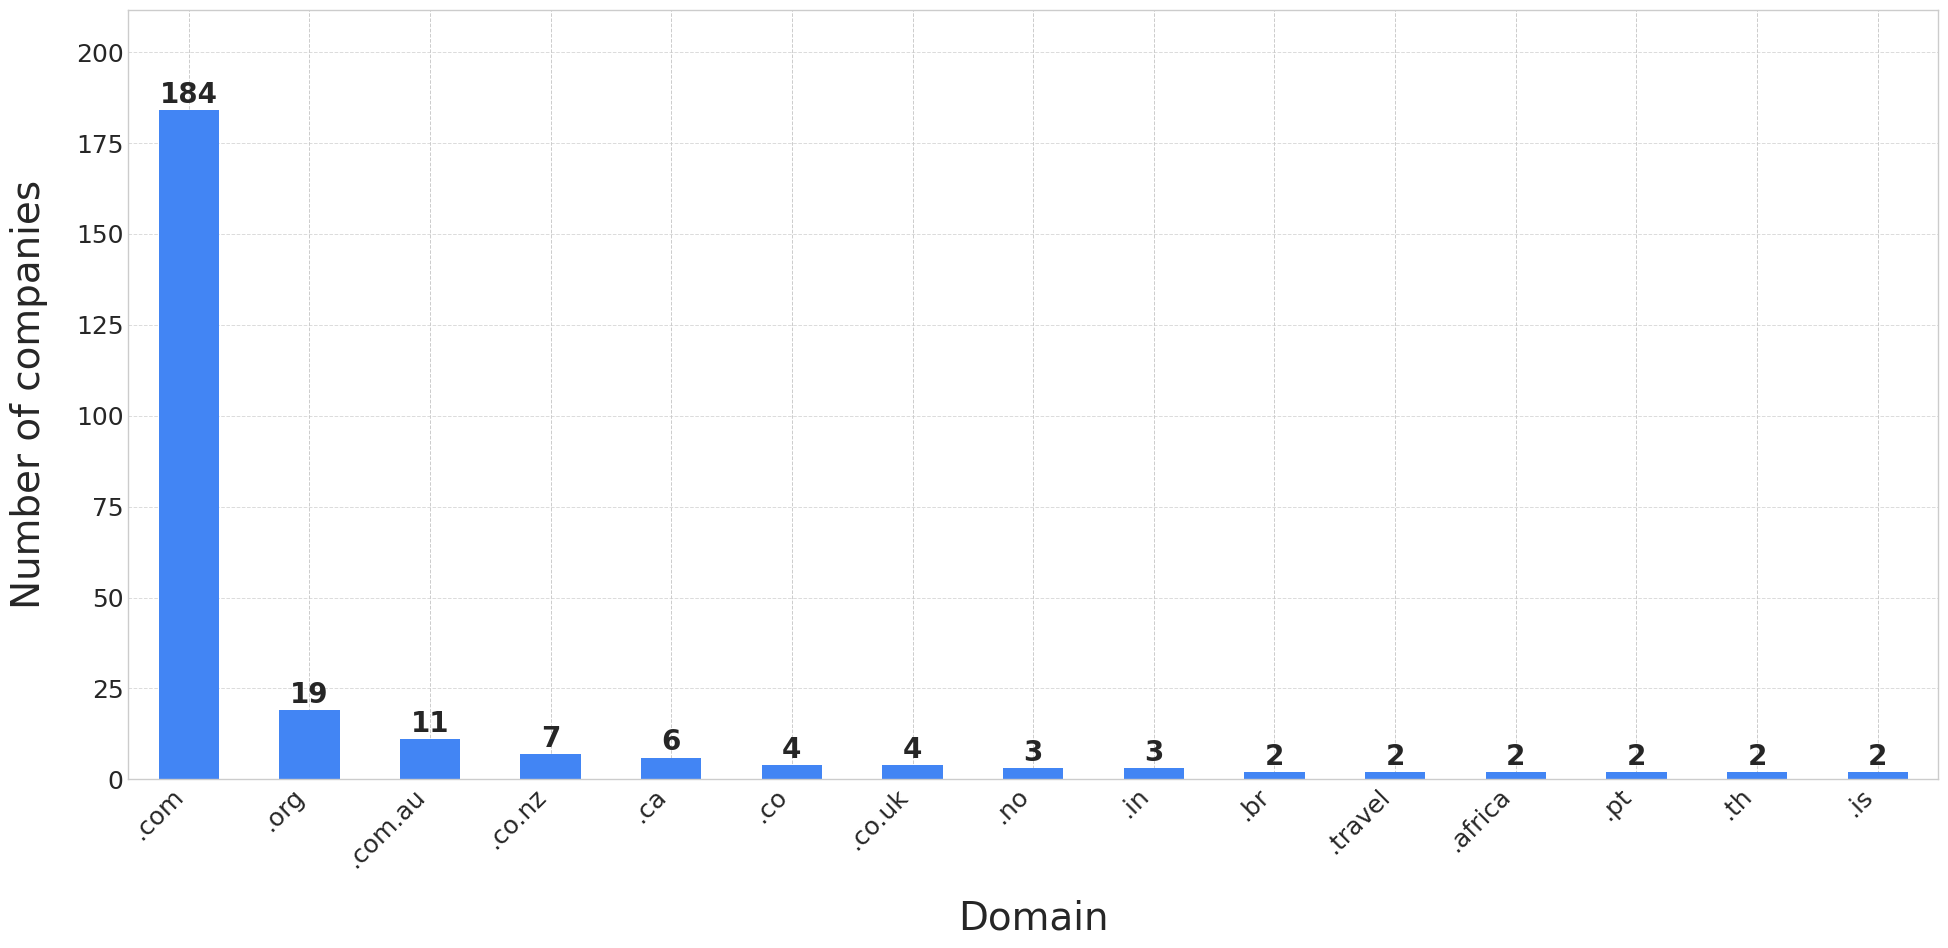

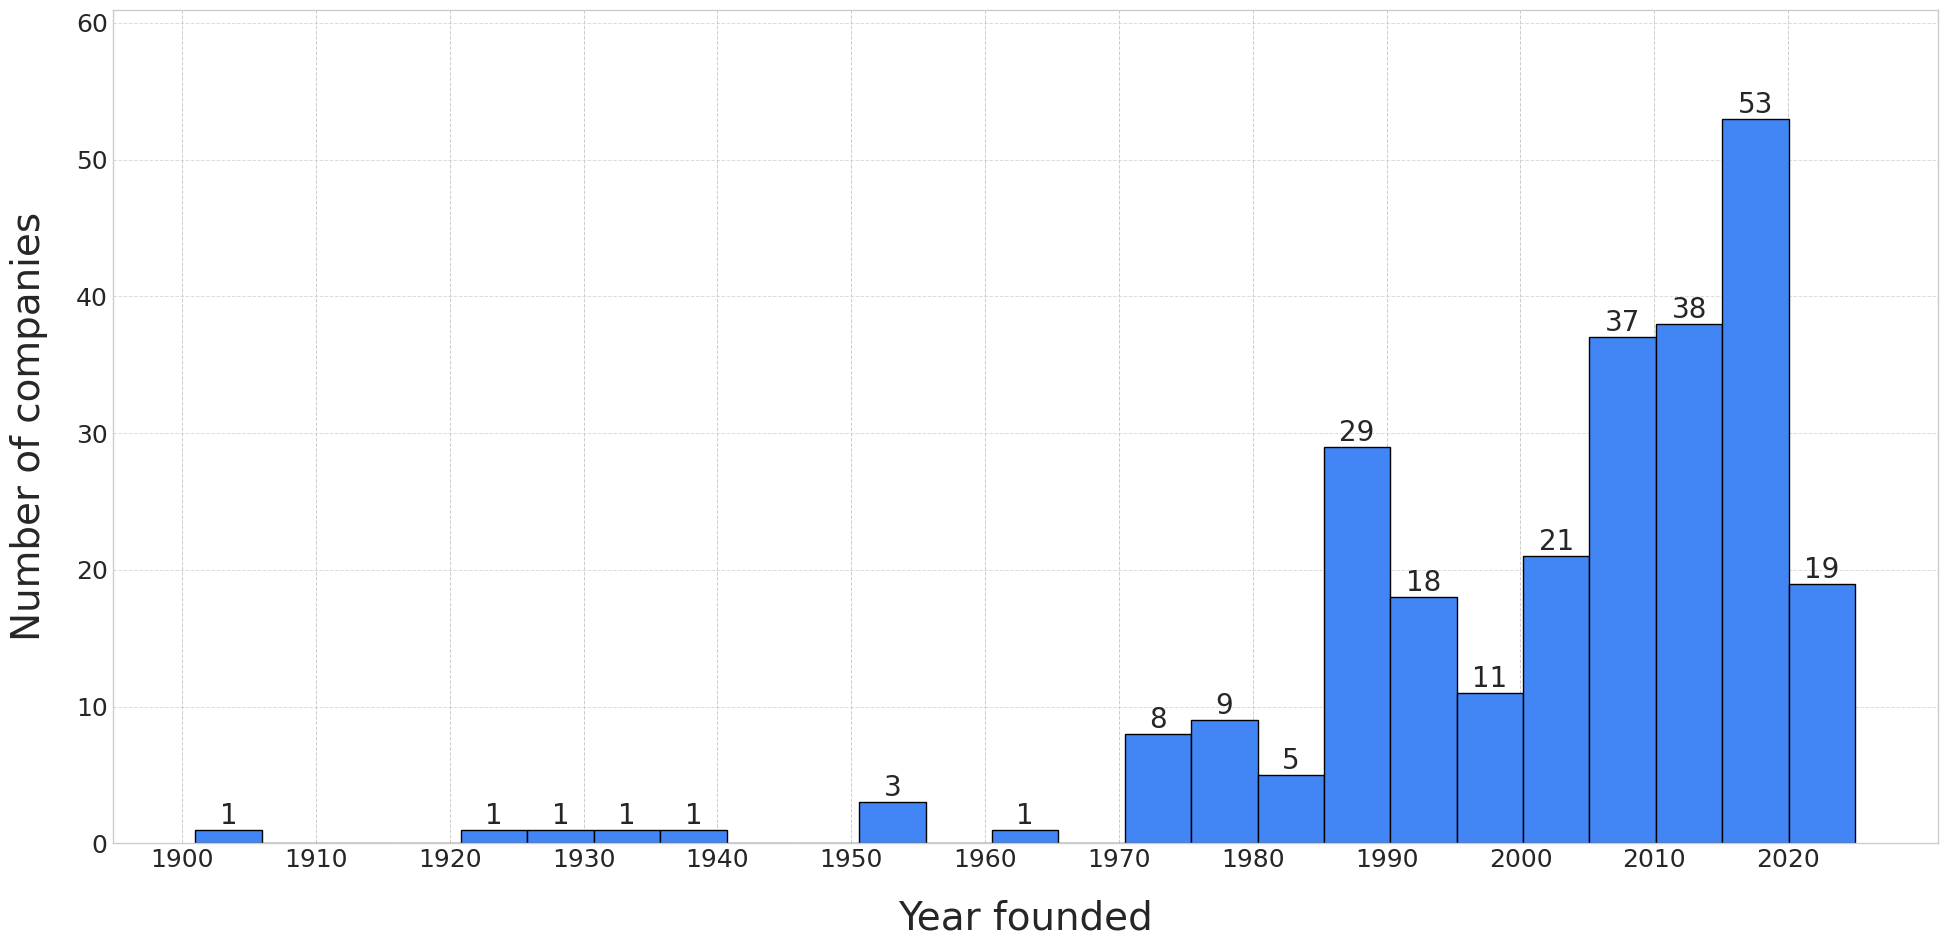

Earliest company: 1901.0
Latest company: 2025.0
Median founding year: 2008

Most common website domains:
 domain
com       184
org        19
com.au     11
co.nz       7
ca          6
co          4
co.uk       4
no          3
in          3
br          2
Name: count, dtype: int64


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd
import numpy as np
import re
from urllib.parse import urlparse

# Clean columns
df["company's website"] = df["company's website"].replace(["0", 0, "", " "], pd.NA)
df["company's foundation year"] = df["company's foundation year "].replace(["0", 0, "", " "], pd.NA)

def extract_domain(url):
    if pd.isna(url) or not isinstance(url, str) or len(url.strip()) == 0:
        return None
    try:
        netloc = urlparse(url).netloc.lower()
        if netloc.startswith("www."):
            netloc = netloc[4:]
        parts = netloc.split(".")

        if len(parts) >= 2:
            if parts[-1] in ["uk", "au", "nz"]:
                return ".".join(parts[-2:])
            return parts[-1]
        return netloc
    except Exception:
        return None

# ---------- GLOBAL PRESENTATION STYLE ----------
plt.rcParams.update({
    "figure.figsize": (20, 10),
    "font.size": 24,
    "axes.labelsize": 28,
    "xtick.labelsize": 18,
    "ytick.labelsize": 18,
})

# ---------- TOP 15 DOMAINS ----------
df["domain"] = df["company's website"].apply(extract_domain)
domain_counts = df["domain"].dropna().value_counts()
top_domains = domain_counts.head(15)

# add dot in front of domain labels for x-axis
top_domains.index = ["." + d for d in top_domains.index]

fig, ax = plt.subplots()

ax = top_domains.plot(kind="bar", color=BAR_COLOR, ax=ax)

# add headroom above tallest bar
y_max = top_domains.max()
ax.set_ylim(0, y_max * 1.15)

plt.xlabel("Domain")
plt.ylabel("Number of companies")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.7)

# value labels – use numeric values, not index
for i, v in enumerate(top_domains.values):
    ax.text(
        i,
        v + 0.3,
        str(int(v)),
        ha="center",
        va="bottom",
        fontsize=20,
        fontweight="bold",
    )

fig.tight_layout()

fig.savefig("domains_600dpi.png", dpi=600, bbox_inches="tight")
fig.savefig("domains.svg", bbox_inches="tight")
fig.savefig("domains.pdf", bbox_inches="tight")

plt.show()



# ---------- FOUNDATION YEAR CLEANING & HISTOGRAM ----------

def extract_year(value):
    """Extract 4-digit year if valid"""
    if pd.isna(value):
        return None
    text = str(value)
    match = re.search(r"(19|20)\d{2}", text)
    return int(match.group()) if match else None

df["year_founded"] = df["company's foundation year "].apply(extract_year)

# Keep valid range (1900–2025)
df_years = df[df["year_founded"].between(1900, 2025, inclusive="both")]

fig2, ax2 = plt.subplots()

# histogram
n, bins, patches = ax2.hist(
    df_years["year_founded"],
    bins=25,
    color=BAR_COLOR,
    edgecolor="black"
)

plt.xlabel("Year founded")
plt.ylabel("Number of companies")
plt.grid(axis="y", linestyle="--", alpha=0.7)

years = sorted(df_years["year_founded"].unique())
start = (min(years) // 5) * 5
end   = (max(years) // 5) * 5
ticks = np.arange(start, end + 1, 10)

ax2.set_xticks(ticks)
ax2.xaxis.set_major_formatter(mticker.FormatStrFormatter('%d'))

# headroom above tallest bar
y_max_hist = max([p.get_height() for p in patches])
ax2.set_ylim(0, y_max_hist * 1.15)

# value labels above bars
for p in patches:
    height = p.get_height()
    if height > 0:
        x = p.get_x() + p.get_width() / 2
        ax2.text(
            x,
            height,
            str(int(height)),
            ha="center",
            va="bottom",
            fontsize=20,
        )

fig2.tight_layout()

fig2.savefig("foundation_years_600dpi.png", dpi=600, bbox_inches="tight")
fig2.savefig("foundation_years.svg", bbox_inches="tight")
fig2.savefig("foundation_years.pdf", bbox_inches="tight")

plt.show()

# ---------- SUMMARY ----------

print("Earliest company:", df_years["year_founded"].min())
print("Latest company:", df_years["year_founded"].max())
print("Median founding year:", int(df_years["year_founded"].median()))
print("\nMost common website domains:\n", domain_counts.head(10))


# Clusterization

Sample cleaned fields:
0           [wildlife, native species]
1    [wetlands, wildlife, agriculture]
2        [agriculture, native species]
3             [marine, native species]
4                                   []
Name: fields_clean, dtype: object
Sample cleaned regions:
0    [latin america & caribbean]
1          [east asia & pacific]
2          [east asia & pacific]
3          [east asia & pacific]
4          [east asia & pacific]
Name: regions_clean, dtype: object
Sample cleaned dev levels:
0    [upper middle income]
1            [high income]
2            [high income]
3            [high income]
4            [high income]
Name: dev_clean, dtype: object
X_fields shape: (273, 5)
field classes: ['forest' 'marine' 'unknown' 'wetlands' 'wildlife']
X_regions shape: (273, 7)
region classes: ['east asia & pacific' 'europe & central asia' 'latin america & caribbean'
 'middle east & north africa' 'north america' 'south asia'
 'sub-saharan africa']
X_dev shape: (273, 4)
dev classes: ['hig

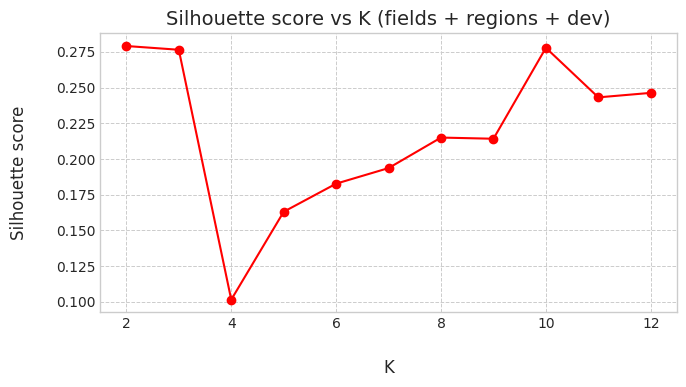


 Best K by silhouette: 2


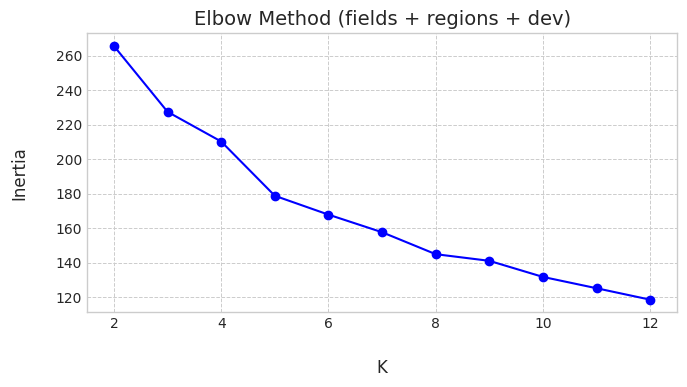


Cluster sizes:
cluster_all
0    143
1    130
Name: count, dtype: int64

==================== CLUSTER SUMMARIES ====================


--- CLUSTER 0 ---
Top fields:
forest            78
native species    55
agriculture       48
wildlife          38
marine            31
reforestation     27
coastal           12
Name: count, dtype: int64

Top regions:
east asia & pacific          41
latin america & caribbean    39
sub-saharan africa           27
europe & central asia        20
north america                18
Name: count, dtype: int64

Top development levels:
high income            77
upper middle income    38
lower middle income    31
low income              8
Name: count, dtype: int64

Total projects: 143
------------------------------------------------------

--- CLUSTER 1 ---
Top fields:
marine               40
wildlife             21
coral reefs          20
pollution cleanup    19
native species       16
coastal              13
seagrass              5
Name: count, dtype: int64

Top r

In [ ]:

# FIELD DEFINITIONS (STRONG + NOISE)


strong_fields = {
    "marine",
    "coastal",
    "coral reefs",
    "seagrass",
    "turtles",
    "oyster",
    "wildlife",
    "native species",
    "wetlands",
    "rainforest",
    "forest",
    "reforestation",
    "pollution cleanup",
    "agriculture",
    "safari",
}

noise_fields = {
    "community",
    "cultural",
    "education",
    "conservation",
    "research",
    "restoration",
    "land regeneration",
    "renewable energy",
    "biodiversity",
}


# CLEAN + FILTER FIELDS (KEEP STRONG, DROP NOISE)

def clean_and_filter_fields(x: str):

    if not isinstance(x, str):
        return []

    parts = [p.strip().lower() for p in x.split(",") if p.strip()]

    cleaned = []
    for f in parts:
        if f in noise_fields:
            continue

        if f in strong_fields:
            cleaned.append(f)

    cleaned = list(dict.fromkeys(cleaned))

    # optionally limit to top N strongest signals per project
    return cleaned[:3]

# apply cleaning to original df["fields"]
df["fields_clean"] = (
    df["fields"]
      .fillna("")
      .astype(str)
      .apply(clean_and_filter_fields)
)

print("Sample cleaned fields:")
print(df["fields_clean"].head())



#  GENERIC CLEANER FOR COMMA-SEPARATED COLUMNS


def clean_multi_simple(x: str):
    """
    For region and country_development_level:
    - splits by comma
    - strips spaces
    - lowercases
    """
    if not isinstance(x, str):
        return []
    return [p.strip().lower() for p in x.split(",") if p.strip()]

# region may be comma-separated: "east asia & pacific, europe"
df["regions_clean"] = (
    df["region"]
      .fillna("")
      .astype(str)
      .apply(clean_multi_simple)
)

# country_development_level may be comma-separated too
df["dev_clean"] = (
    df["country_development_level"]
      .fillna("")
      .astype(str)
      .apply(clean_multi_simple)
)
df["group_clean"] = (
    df["ecosystem_group"]
      .fillna("")
      .astype(str)
      .apply(clean_multi_simple)
)


print("Sample cleaned regions:")
print(df["regions_clean"].head())
print("Sample cleaned dev levels:")
print(df["dev_clean"].head())




mlb_fields = MultiLabelBinarizer()
X_fields = mlb_fields.fit_transform(df["group_clean"])
print("X_fields shape:", X_fields.shape)
print("field classes:", mlb_fields.classes_)



mlb_regions = MultiLabelBinarizer()
X_regions = mlb_regions.fit_transform(df["regions_clean"])
print("X_regions shape:", X_regions.shape)
print("region classes:", mlb_regions.classes_)


mlb_dev = MultiLabelBinarizer()
X_dev = mlb_dev.fit_transform(df["dev_clean"])
print("X_dev shape:", X_dev.shape)
print("dev classes:", mlb_dev.classes_)






w_fields = 1.0      # strongest semantic signal
w_regions = 0.7     # geography
w_dev = 0.5         # development level

X = hstack(
    [
        csr_matrix(X_fields) * w_fields,
        csr_matrix(X_regions) * w_regions,
        csr_matrix(X_dev) * w_dev,
    ],
    format="csr",
)

print("Final X shape:", X.shape)



# SILHOUETTE ANALYSIS


sil_scores = []
K_values = range(2, 13)

for k in K_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X)
    score = silhouette_score(X, labels, metric="cosine")
    sil_scores.append(score)
    print(f"K={k}: silhouette={score:.3f}")

plt.figure(figsize=(7, 4))
plt.plot(K_values, sil_scores, "o-r")
plt.title("Silhouette score vs K (fields + regions + dev)")
plt.xlabel("K")
plt.ylabel("Silhouette score")
plt.grid(True)
plt.tight_layout()
plt.show()

best_k_sil = K_values[sil_scores.index(max(sil_scores))]
print("\n Best K by silhouette:", best_k_sil)



# ELBOW METHOD


inertias = []
for k in K_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X)
    inertias.append(km.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(K_values, inertias, "o-b")
plt.title("Elbow Method (fields + regions + dev)")
plt.xlabel("K")
plt.ylabel("Inertia")
plt.grid(True)
plt.tight_layout()
plt.show()



#  FINAL CLUSTERING


km_final = KMeans(n_clusters=best_k_sil, random_state=42, n_init=20)
df["cluster_all"] = km_final.fit_predict(X)

print("\nCluster sizes:")
print(df["cluster_all"].value_counts().sort_index())



# CLUSTER SUMMARIES (WHAT EACH CLUSTER IS ABOUT)


print("\n==================== CLUSTER SUMMARIES ====================\n")

for c in sorted(df["cluster_all"].unique()):
    cl = df[df["cluster_all"] == c]

    all_fields = [f for row in cl["fields_clean"] for f in row]
    top_fields = pd.Series(all_fields).value_counts().head(7)

    all_regions = [r for row in cl["regions_clean"] for r in row]
    top_regions = pd.Series(all_regions).value_counts().head(5)

    all_dev = [d for row in cl["dev_clean"] for d in row]
    top_dev = pd.Series(all_dev).value_counts().head(5)

    print(f"\n--- CLUSTER {c} ---")
    print("Top fields:")
    print(top_fields)
    print("\nTop regions:")
    print(top_regions)
    print("\nTop development levels:")
    print(top_dev)
    print("\nTotal projects:", len(cl))
    print("------------------------------------------------------")


The feature-based K-Means model with K = 2 produced two thematically coherent clusters, with a silhouette score of 0.279, indicating a weak–moderate but meaningful separation in this type of real-world ecological data. Despite the moderate score, the clusters demonstrated clear ecological and geographic distinctions that align with known patterns in regenerative tourism.

The first cluster consists predominantly of land-based and terrestrial regeneration projects, characterized by strong representation in fields such as forests, native species restoration, agriculture, wildlife conservation, and reforestation. Geographically, this cluster spans a broad global distribution across East Asia & Pacific, Latin America & Caribbean, Sub-Saharan Africa, Europe & Central Asia, and North America. In terms of development levels, it includes projects from countries of all income categories, reflecting the universal relevance of land and forest restoration activities.

The second cluster is primarily composed of marine and coastal regeneration projects, including initiatives focused on coral reefs, seagrass, turtles, and broader marine ecosystem restoration. These projects are more concentrated in higher-income countries, especially in Europe & Central Asia and coastal regions of East Asia & Pacific. This cluster captures initiatives where regenerative tourism is closely connected with ocean conservation, coastal protection, and underwater biodiversity.

Overall, the two clusters represent two distinct ecological domains within regenerative tourism:
(1) terrestrial and forest-focused regeneration, and
(2) marine and coastal ecosystem restoration.

This confirms that the dataset naturally separates into meaningful environmental themes, demonstrating that even with moderate silhouette values, K-Means can capture interpretable and actionable structure in complex ecological data.

# Clustering with description

Total rows: 273
Rows with non-empty descriptions: 240


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

...

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/8 [00:00<?, ?it/s]

Embeddings shape: (240, 384)
K=2: silhouette=0.071
K=3: silhouette=0.059
K=4: silhouette=0.064
K=5: silhouette=0.059
K=6: silhouette=0.059
K=7: silhouette=0.051
K=8: silhouette=0.042
K=9: silhouette=0.048
K=10: silhouette=0.049


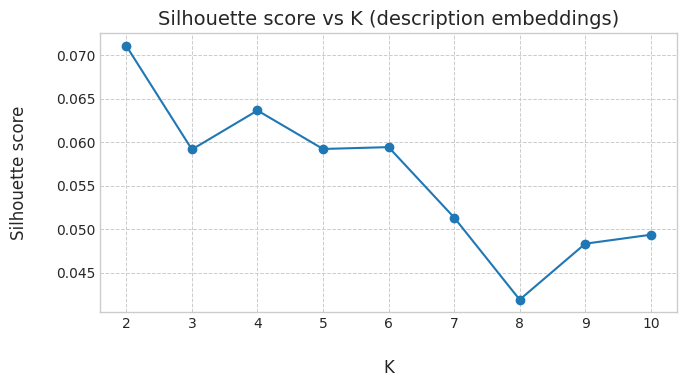


 Best K by silhouette: 2

Cluster sizes (non-empty descriptions only):
0    126
1    114
Name: count, dtype: int64

==================== CLUSTER SUMMARIES (DESCRIPTION-BASED) ====================


--- CLUSTER 0 ---
Total projects: 126
Example descriptions:
1. Lady Elliot Island Eco Resort actively practices regenerative tourism through a multi-faceted approach to environmental restoration.  The resort has been the site of a multi-year project to restore the island's terrestrial ecosystem, supported by par
2. The Tourism CoLab it's online education platform and global community of regenerative tourism practitioners.  Tourism CoLab's approach to regenerative tourism focuses on building the capacity of communities, businesses, and governments to collaborati
3. The Islander Way is a regenerative tourism project focused on Flinders Island, Australia. The project aims to co-design the future of tourism with the community, creating a system that respects their values, builds a resilient eco

In [ ]:

TEXT_COL = "short description"

# Clean descriptions
df[TEXT_COL] = (
    df[TEXT_COL]
      .fillna("")
      .astype(str)
      .str.strip()
)

# Keep mask of non-empty descriptions (we can't embed empty strings meaningfully)
mask_nonempty = df[TEXT_COL].str.len() > 0
texts = df.loc[mask_nonempty, TEXT_COL].tolist()

print(f"Total rows: {len(df)}")
print(f"Rows with non-empty descriptions: {len(texts)}")


# EMBEDDINGS WITH SENTENCE-TRANSFORMERS


model = SentenceTransformer("all-MiniLM-L6-v2")

embeddings = model.encode(
    texts,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)

print("Embeddings shape:", embeddings.shape)


#  FIND GOOD K (NUMBER OF CLUSTERS)


K_values = range(2, 11)
sil_scores = []

for k in K_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels_k = km.fit_predict(embeddings)
    score = silhouette_score(embeddings, labels_k, metric="cosine")
    sil_scores.append(score)
    print(f"K={k}: silhouette={score:.3f}")


plt.figure(figsize=(7, 4))
plt.plot(list(K_values), sil_scores, "o-")
plt.title("Silhouette score vs K (description embeddings)")
plt.xlabel("K")
plt.ylabel("Silhouette score")
plt.grid(True)
plt.tight_layout()
plt.show()


best_k = list(K_values)[int(np.argmax(sil_scores))]
print("\n Best K by silhouette:", best_k)

# FINAL KMEANS CLUSTERING


kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=50)
cluster_labels = kmeans.fit_predict(embeddings)

# Create a full-length array with NaN for empty descriptions
df["cluster_desc"] = np.nan
df.loc[mask_nonempty, "cluster_desc"] = cluster_labels

print("\nCluster sizes (non-empty descriptions only):")
print(pd.Series(cluster_labels).value_counts().sort_index())



print("\n==================== CLUSTER SUMMARIES (DESCRIPTION-BASED) ====================\n")

MAX_EXAMPLES = 5

for c in sorted(pd.Series(cluster_labels).unique()):
    cl_idx = np.where(cluster_labels == c)[0]
    print(f"\n--- CLUSTER {c} ---")
    print(f"Total projects: {len(cl_idx)}")
    print("Example descriptions:")

    examples = df.loc[mask_nonempty, TEXT_COL].iloc[cl_idx].head(MAX_EXAMPLES)
    for i, text in enumerate(examples, start=1):
        print(f"{i}. {text[:250].replace('\n', ' ')}")
    print("------------------------------------------------------")


The description-based clustering approach also produced two distinct and highly interpretable clusters, confirming that regenerative tourism projects naturally separate into meaningful thematic groups when analyzed through their narrative descriptions. Compared to feature-based clustering, this method revealed even clearer ecological and conceptual boundaries.

The first description-based cluster is dominated by projects focused on marine, coastal, and island ecosystem regeneration. The example descriptions emphasize coral nurseries, reef restoration, island ecosystem recovery, partnerships with marine scientists, and tourism models that directly support ocean conservation activities. This cluster captures initiatives where regenerative tourism functions as a mechanism for restoring underwater biodiversity, strengthening reef resilience, and protecting fragile coastal environments. The thematic coherence of this cluster indicates that marine-oriented projects share highly consistent language and conceptual framing.   

The second description-based cluster is centered on land-based restoration, rewilding, regenerative agriculture, and cultural landscape stewardship. The projects in this cluster frequently describe soil regeneration, wildlife habitat enhancement, expansion of protected lands, Indigenous land management practices, and strong community engagement. These narratives focus on restoring terrestrial ecosystems, supporting native species, and strengthening social-ecological resilience at the landscape level. The presence of cultural and community dimensions is particularly pronounced, reflecting the holistic approach typical of regenerative land management.

Overall, the description-based clustering reveals two robust thematic domains within regenerative tourism narratives:
(1) marine and island ecosystem restoration, and
(2) land and cultural landscape regeneration.

This confirms that the textual content of project descriptions contains strong semantic structure, allowing the model to differentiate between marine-focused and land-focused restoration approaches. The coherence of these clusters supports the validity of the description-based method and reinforces the ecological distinctions observed in the feature-based clustering.

# Word clouds on KMean

/usr/local/lib/python3.12/dist-packages/sklearn/feature_extraction/text.py:402: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['hawai', 'ian'] not in stop_words.
  warnings.warn(


TF-IDF shape for word clouds: (240, 1184)
Saved cluster_0_wordcloud_600dpi.png (projects in cluster 0: 126)


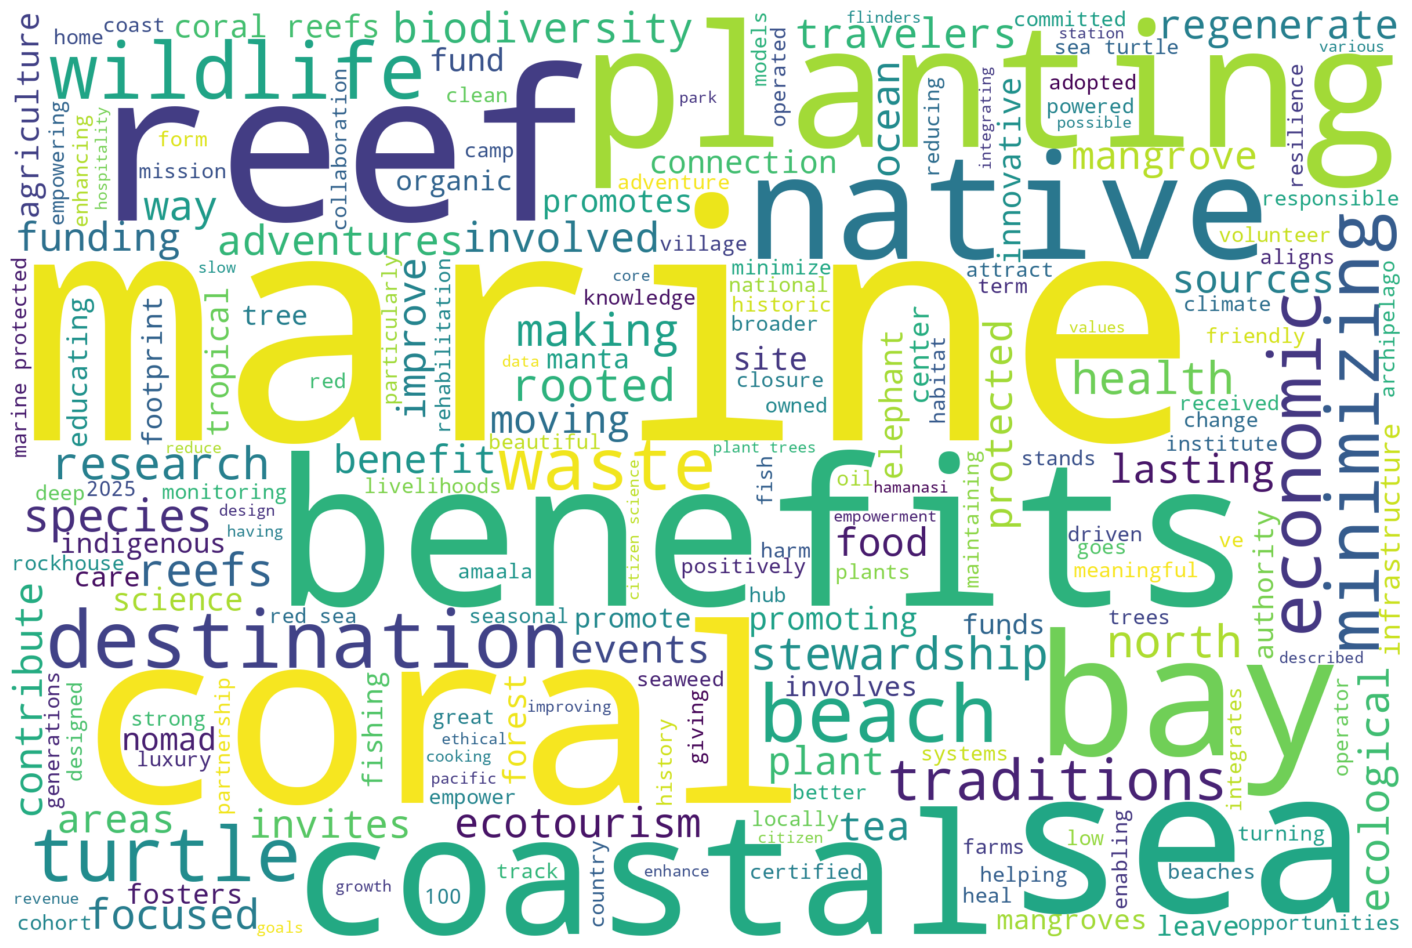

Saved cluster_1_wordcloud_600dpi.png (projects in cluster 1: 114)


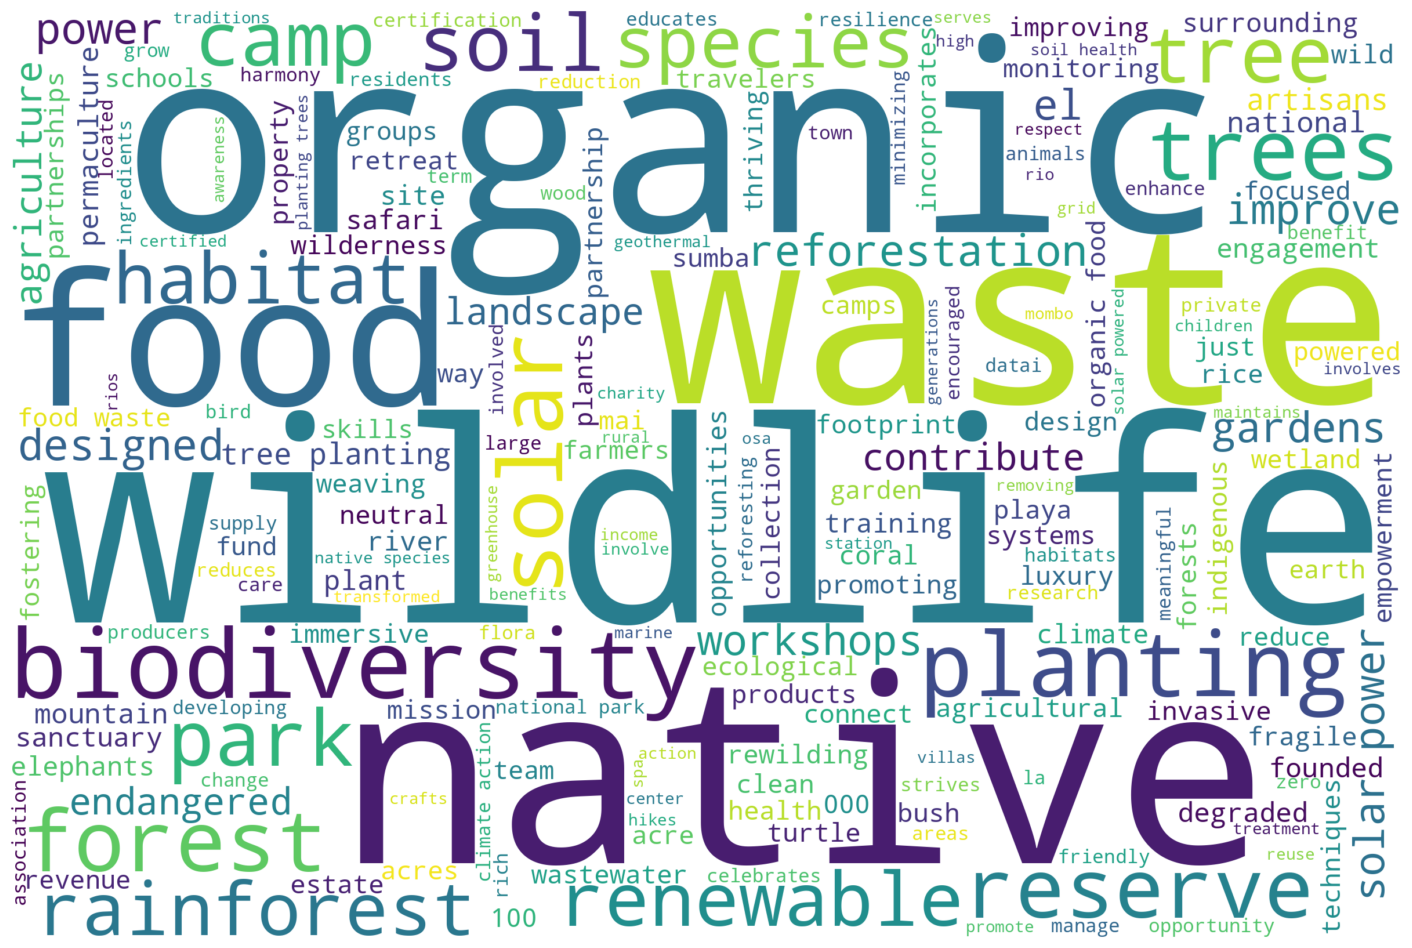

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from wordcloud import WordCloud
import numpy as np
import matplotlib.pyplot as plt

TEXT_COL = "short description"

df[TEXT_COL] = (
    df[TEXT_COL]
      .fillna("")
      .astype(str)
      .str.strip()
)

mask_nonempty = df[TEXT_COL].str.len() > 0
cluster_df = df.loc[mask_nonempty, [TEXT_COL, "cluster_desc"]].copy()

custom_stop_words = {
    # tourism / hospitality generic words
    "tourism", "tourist", "tourists", "travel", "tours", "tour",
    "experience", "experiences", "visitors", "visitor",
    "guest", "guests", "stay", "stays",
    "resort", "resorts", "hotel", "hotels", "lodge", "lodges",

    # sustainability generic words
    "regenerative", "regeneration", "sustainable", "sustainability",
    "eco", "green", "environment", "environmental",

    # project-structure words
    "project", "projects", "initiative", "initiatives",
    "program", "programs", "model", "approach",

    # generic “community / location” words
    "local", "locals", "community", "communities",
    "area", "region", "place", "places",

    # generic verbs and functional words
    "support", "supports", "supporting",
    "create", "creates", "creating",
    "use", "uses", "using", "used",
    "focus", "focuses", "focusing",
    "provide", "provides", "providing",
    "offer", "offers", "offering",
    "include", "includes", "including",
    "engage", "engages", "engaging",
    "considered", "working", "work", "works",
    "allow", "allows", "help", "helps",
    "join", "participate", "participating",

    # generic adjectives (too broad)
    "positive", "negative", "unique", "authentic",
    "healthy", "long", "future",

    # generic nouns that don't differentiate clusters
    "impact", "impacts", "life", "people",
    "activities", "activity",
    "effort", "efforts",
    "practices", "practice",
    "social", "economy",

    # restoration words (too common across all clusters)
    "restore", "restores", "restoring", "restoration",

    # other overly common cluster words
    "actively", "like", "led", "based", "aims", "goal",
    "development", "initiatives", "principles",
    "directly", "resources", "materials", "new", "partners",

    "ecosystem", "ecosystems",
    "natural", "nature",
    "land",
    "water",
    "energy",
    "carbon",

    "company", "companies",
    "business", "businesses",
    "farm", "farming",
    "culture", "cultural", "traditional", "tradition", "heritage",
    "island", "islands",
    "building", "built",

    "hawaii", "hawaiian", "australia", "africa", "thailand",
    "koh", "patagonia", "aotearoa", "bhutan", "new", "zealand",
    "hawaiʻi",   # with the special okina character
    "hawai'i",   # apostrophe version
    "hawaiʻian",
    "hawai'ian",

    # too generic scientific/action verbs
    "contributes", "contributing", "contribution",
    "example", "examples",
    "preserve", "preserving", "preservation",
    "management",
    "ensuring", "ensure",
    "education", "educational", "educate", "learning", "learn",
    "commitment",
    "foundation", "foundations",
    "organization", "organizations",
    "dedicated", "capacity",
    "run", "operates", "operate", "operation", "operations",
    "world", "global",

    # conservation family
    "conservation", "conserving", "conserves",

    # protect family
    "protect", "protects", "protecting", "protection",
}

# combine default English stop words with your domain stop words
stop_words_wc = ENGLISH_STOP_WORDS.union(custom_stop_words)
stop_words_wc = list(stop_words_wc)

vectorizer_wc = TfidfVectorizer(
    max_features=5000,
    stop_words=stop_words_wc,
    ngram_range=(1, 2),
    min_df=2,
)

tfidf_all = vectorizer_wc.fit_transform(cluster_df[TEXT_COL])
terms = vectorizer_wc.get_feature_names_out()

print("TF-IDF shape for word clouds:", tfidf_all.shape)

unique_clusters = sorted(cluster_df["cluster_desc"].dropna().unique().astype(int))

# Big figure default for projector
plt.rcParams.update({
    "figure.figsize": (20, 10),
})

for c in unique_clusters:
    mask_c = (cluster_df["cluster_desc"] == c).values
    rows_c = tfidf_all[mask_c]

    weights = np.asarray(rows_c.sum(axis=0)).ravel()

    word_weights = {
        term: float(w)
        for term, w in zip(terms, weights)
        if w > 0
    }

    if not word_weights:
        print(f"Cluster {c} has no words with positive TF-IDF, skipping word cloud.")
        continue

    # Higher-resolution word cloud image
    wc = WordCloud(
        width=2400,          # more pixels than before
        height=1600,
        background_color="white"
    ).generate_from_frequencies(word_weights)

    fig, ax = plt.subplots()     # uses (20, 10) from rcParams
    ax.imshow(wc, interpolation="bilinear")
    ax.axis("off")
    fig.tight_layout()

    base_name = f"cluster_{c}_wordcloud"

    # High-quality exports
    fig.savefig(f"{base_name}_600dpi.png", dpi=600, bbox_inches="tight")
    fig.savefig(f"{base_name}.pdf", bbox_inches="tight")
    fig.savefig(f"{base_name}.svg", bbox_inches="tight")

    print(f"Saved {base_name}_600dpi.png (projects in cluster {c}: {mask_c.sum()})")

    plt.show()


In [ ]:
cluster_sizes = (
    df.loc[mask_nonempty, "cluster_desc"]
      .value_counts()
      .sort_index()
      .rename("n_projects")
)

print(cluster_sizes)


cluster_desc
0.0    126
1.0    114
Name: n_projects, dtype: int64
